# 03 · Signatures — embryonic-development module scores & Gate 2

Score each cell for the three embryonic modules (**Gast** gastrulation, **pSom**
posterior somitogenesis, **Crest** neural crest) with `score_genes` against the
shared **union** control pool. The manifold is non-branching, so Gate 2 is read as
one graded developmental gradient along pseudotime, not as competing branch fates.
**Gate 2 = GO** if Gast/pSom co-localise at the origin and decline while Crest rises
to a terminal readout (Crest anti-correlated with both, not a Gast-arm enrichment).

In [1]:
%matplotlib inline
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer','vertebrate','CCCA','Claude',cat,name)
pth_feat = os.path.join(pth_data,'features','biomart')
pth_fig = os.path.join(pth,'figures','cancer','vertebrate','CCCA','Claude',cat,name)
pth_cb = os.path.join(pth_fig,'colorbars')
os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 02)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out,'manifold.h5ad'))
modules = {'Gast':'Gastrulation','pSom':'Somitogenesis','Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| raw module means:',
      {m: round(float(adata.obs[m].mean()),4) for m in modules})

cells: 1082 | raw module means: {'Gast': -0.0152, 'pSom': 0.0158, 'Crest': -0.0022}


### Gate 2 — module geography (quantitative, on the smoothed scores)
(i) Gast & pSom spatial correlation; (ii) Crest vs both; (iii) joint-high enrichment
(>1 = co-expression hub, <1 = inverse/mutually-exclusive gradient); (iv) pseudotime
gradients + Crest terminal decile.

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
gh = adata.obs['Gast_sm'] > adata.obs['Gast_sm'].quantile(0.66)
ph = adata.obs['pSom_sm'] > adata.obs['pSom_sm'].quantile(0.66)
enr = (gh & ph).mean() / (gh.mean()*ph.mean())
print(f'joint Gast&pSom-high enrichment = {enr:.2f}  (>1 hub / <1 inverse gradient)')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho, smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
_crest_rho = spearmanr(t, adata.obs['Crest_sm'])[0]
assert enr < 1 and _crest_rho > 0.2, 'Gate 2 FAILED: not an inverse terminal-Crest gradient'
print('Gate 2: Gast/pSom origin -> terminal Crest, inverse gradient (enr<1) -> GO (non-branching)')
print('Gate 3: no bifurcation hub -> NA')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.60
  Crest_sm vs Gast_sm: r = -0.37
  Crest_sm vs pSom_sm: r = -0.43
joint Gast&pSom-high enrichment = 0.20  (>1 hub / <1 inverse gradient)
gradient along pseudotime (Spearman rho, smoothed):
  Gast_sm: rho = -0.469
  pSom_sm: rho = +0.052
  Crest_sm: rho = +0.586
Neural-crest-high decile mean pseudotime = 1.00 (terminal if ~1)
Gate 2: Gast/pSom origin -> terminal Crest, inverse gradient (enr<1) -> GO (non-branching)
Gate 3: no bifurcation hub -> NA


### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`, plasma. Maps show
the **raw** (unsmoothed) per-cell scores (smoothing is used only for the geography
statistics above). Colorbar ticks are data-driven from each score's range.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


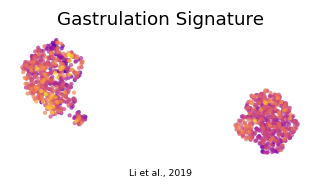

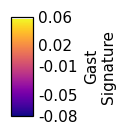

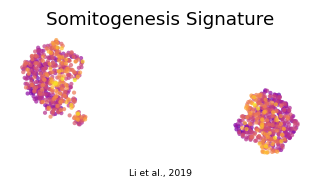

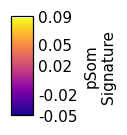

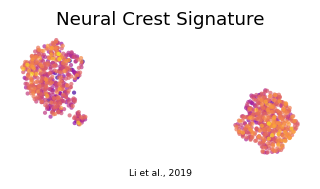

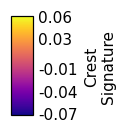

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Li et al., 2019', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo,hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo,hi,5),2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [6]:
adata.write(os.path.join(pth_out,'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (1082, 18161)
